# Miniature adaptive monotherapy screen — custom Gibbs

Repeat notebook 1.0 with `BayesianFixedDoseModel(sampler=GibbsSampler(...))`, preserving the response preparation, random seed and RNG call order, nested 2/6/10 backgrounds, supported pool capped at 256 compounds, 16 initial target observations, and ten rounds of eight acquisitions. More negative LFC means stronger killing. The fixed hit set is the pool's lowest-LFC ceil(10% × pool size), ties broken by compound ID; retrieval includes the initial measurements.

Four chains run sequentially, each with 40 warmup sweeps and 60 post-warmup sweeps (30 retained for predictions at thinning 2). This matches the updated PyMC demo's sampling counts, not equal compute or demonstrated convergence. Gibbs does not use `target_accept` or `max_treedepth`.

The existing simulation and selectors are unchanged. Each fitted posterior, training dataset, prediction table and timing record is saved under `output/demo_sampler_comparison/gibbs`. Hidden target responses are used only for reveals and retrospective scoring, not model fitting or selection before they are revealed. The random baseline still runs through the same fit interface, although its choices ignore predictions.

**Executed result:** target ACH-000922, dose 2.5, 154 supported compounds. All three Gibbs trajectories retrieved 16/16 top hits by 96 target measurements; random retrieved 11/16 (68.75%). This is a single-target demonstration, not convergence or general efficacy evidence. Notebook 1.2 reads the saved traces without fitting anything.

In [ ]:
from pathlib import Path
import sys
import json
import hashlib
import resource
from time import perf_counter
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from threadpoolctl import threadpool_limits

from nbutils.batchie_mono.factorization_model import BayesianFixedDoseModel
from nbutils.batchie_mono.gibbs import GibbsSampler
from nbutils.batchie_mono.simulation import run_simulation
from nbutils.batchie_mono.model_acquisition import PredictedLowestSelector, RandomSelector
from nbutils.batchie_mono.sampling import SamplingConfig
from nbutils.batchie_mono.spec import ModelSpec

repo_root = next(path for path in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
                 if (path / "pyproject.toml").exists() and (path / "data").is_dir())

backend = "gibbs"
model_spec = ModelSpec(rank=4)
sampling_config = SamplingConfig(
    burnin=200, 
    posterior_samples=100, 
    thin=2,
    chains=4, 
    cores=16, 
    blas_cores=1,
)
sampler_settings = sampling_config.model_dump()

output_dir = repo_root / "output/demo_sampler_comparison" / backend
output_dir.mkdir(parents=True, exist_ok=True)
print(f"Backend: {backend}; Python: {sys.executable}; model: {model_spec.model_dump()}; settings: {sampler_settings}")

Backend: gibbs; Python: /home/weishanli/anaconda3/envs/dspy-litl-env/bin/python; model: {'rank': 4, 'prior_shape': 1.1, 'prior_rate': 1.1, 'global_precision': 0.01}; settings: {'burnin': 200, 'posterior_samples': 100, 'thin': 2, 'chains': 4, 'seed': 0, 'cores': 16, 'blas_cores': 1}


In [2]:
response_file = repo_root / "data/secondary-screen-observed-response-long.parquet"
if not response_file.exists():
    raise FileNotFoundError(f"Response file does not exist: {response_file}")
keys = ["ModelID", "broad_id", "dose"]
responses = pd.read_parquet(response_file, columns=[*keys, "logfold_change"])
responses.head()

,ModelID,broad_id,dose,logfold_change
0,ACH-000001,BRD-K44408410-001-17-6,0.00061,0.164948
1,ACH-000001,BRD-K44408410-001-17-6,0.00244,-0.647867
2,ACH-000001,BRD-K44408410-001-17-6,0.03910,-0.241189
3,ACH-000001,BRD-K44408410-001-17-6,0.15625,0.176981
4,ACH-000001,BRD-K44408410-001-17-6,0.62500,-0.223823


In [3]:
# Identical response-blind selection and RNG call order to notebook 1.0.
seed = 0
rng = np.random.default_rng(seed)
initial_size, batch_size, iterations = 16, 8, 10
pool_size = 256
background_counts = [2, 6, 10]
fixed_dose = responses.groupby("dose").size().idxmax()
fixed = (
    responses.loc[responses["dose"].eq(fixed_dose)]
    .dropna(subset=[*keys, "logfold_change"])
    .groupby(keys, as_index=False)["logfold_change"].mean()
)
coverage = fixed.groupby("ModelID")["broad_id"].nunique()
eligible = coverage[coverage >= initial_size + batch_size * iterations].index
target_model = str(rng.choice(eligible))
other_models = rng.choice(coverage.index[coverage.index != target_model],
                          size=max(background_counts), replace=False)
smallest_background = fixed[fixed["ModelID"].isin(other_models[:2])]
target_responses = fixed[
    fixed["ModelID"].eq(target_model)
    & fixed["broad_id"].isin(smallest_background["broad_id"])
]
target_responses = target_responses.sample(
    n=min(pool_size, len(target_responses)), random_state=seed,
).reset_index(drop=True)
if len(target_responses) < initial_size + batch_size * iterations:
    raise ValueError("Not enough target responses to match the required pool size.")
backgrounds = {
    count: fixed[
        fixed["ModelID"].isin(other_models[:count])
        & fixed["broad_id"].isin(target_responses["broad_id"])
    ].copy()
    for count in background_counts
}
initial_compounds = target_responses.sample(n=initial_size, random_state=seed)["broad_id"].tolist()
print(f"Target: {target_model} | fixed dose: {fixed_dose:g}")
print(f"Background models: {other_models}")
print(f"Shared pool: {len(target_responses)} compounds (cap {pool_size}) | backgrounds: {background_counts}")
print(f"Shared initial observations: {initial_size} | acquisition: {iterations} × {batch_size}")

Target: ACH-000922 | fixed dose: 2.5
Background models: ['ACH-000701' 'ACH-000086' 'ACH-000569' 'ACH-000320' 'ACH-000362'
 'ACH-000211' 'ACH-000018' 'ACH-000886' 'ACH-000046' 'ACH-000724']
Shared pool: 154 compounds (cap 256) | backgrounds: [2, 6, 10]
Shared initial observations: 16 | acquisition: 10 × 8


In [4]:
# Persist each fitted posterior without changing run_simulation or either selector.
def cpu_seconds():
    return sum(getattr(resource.getrusage(who), name)
               for who in (resource.RUSAGE_SELF, resource.RUSAGE_CHILDREN)
               for name in ("ru_utime", "ru_stime"))

class SavedDemoModel(BayesianFixedDoseModel):
    def __init__(self, label):
        super().__init__(
            sampler=GibbsSampler(config=sampling_config),
            spec=model_spec,
            prediction_seed=seed,
        )
        self.label = label
        self.fit_number = 0

    def fit(self, observed_data):
        self.fit_number += 1
        fit_dir = output_dir / self.label / f"fit_{self.fit_number:02d}"
        fit_dir.mkdir(parents=True, exist_ok=True)
        training_bytes = observed_data[keys + ["logfold_change"]].to_csv(index=False).encode()
        start, cpu_start = perf_counter(), cpu_seconds()
        with threadpool_limits(limits=1):
            super().fit(observed_data)
        wall, cpu = perf_counter() - start, cpu_seconds() - cpu_start
        record = dict(backend=backend, run=self.label, fit=self.fit_number,
                      target_model=target_model, target_observations=initial_size + (self.fit_number - 1) * batch_size,
                      training_rows=len(observed_data), training_sha256=hashlib.sha256(training_bytes).hexdigest(),
                      wall_seconds=wall, cpu_seconds=cpu, seed=seed,
                      model_spec=model_spec.model_dump(), sampler=sampler_settings)
        self.inference_data_.to_netcdf(fit_dir / "trace.nc")
        observed_data.to_csv(fit_dir / "observed.csv", index=False)
        self.predict(target_responses[keys]).to_csv(fit_dir / "predictions.csv", index=False)
        (fit_dir / "fit.json").write_text(json.dumps(record, indent=2))
        print(f"{backend} {self.label} fit {self.fit_number:02d}: {wall:.1f}s", flush=True)
        return self

target_responses.to_csv(output_dir / "target.csv", index=False)
for count, background in backgrounds.items():
    background.to_csv(output_dir / f"background_{count}.csv", index=False)
manifest = dict(backend=backend, target_model=target_model, fixed_dose=float(fixed_dose),
                pool_size=len(target_responses), requested_pool_size=pool_size,
                background_counts=background_counts, background_models=other_models.tolist(),
                initial_compounds=initial_compounds, initial_size=initial_size,
                batch_size=batch_size, iterations=iterations, seed=seed,
                model_spec=model_spec.model_dump(), sampler=sampler_settings)
(output_dir / "manifest.json").write_text(json.dumps(manifest, indent=2))

runs = []
for count in background_counts:
    result = run_simulation(
        background=backgrounds[count], target_responses=target_responses,
        initial_compounds=initial_compounds, model=SavedDemoModel(f"predicted_lowest_b{count}"),
        selector=PredictedLowestSelector(), batch_size=batch_size, iterations=iterations,
    )
    result["background_cells"] = count
    result["background_measurements"] = len(backgrounds[count])
    runs.append(result)
    result.to_csv(output_dir / f"retrieval_b{count}.csv", index=False)
    print(f"{count} background lines: retrieved {result.iloc[-1]['top_10pct_retrieval']:.1%} of top hits")

random_baseline = run_simulation(
    background=backgrounds[2], target_responses=target_responses,
    initial_compounds=initial_compounds, model=SavedDemoModel("random_b2"),
    selector=RandomSelector(seed=seed), batch_size=batch_size, iterations=iterations,
)
random_baseline["background_cells"] = 2
random_baseline["background_measurements"] = len(backgrounds[2])
metrics = pd.concat([*runs, random_baseline], ignore_index=True)
metrics.to_csv(output_dir / "metrics.csv", index=False)
print(f"Saved 40 fits and retrieval metrics to {output_dir}")
metrics.groupby(["selector", "background_cells"]).tail(1)

gibbs predicted_lowest_b2 fit 01: 7.5s
gibbs predicted_lowest_b2 fit 02: 7.5s
gibbs predicted_lowest_b2 fit 03: 7.4s
gibbs predicted_lowest_b2 fit 04: 7.4s
gibbs predicted_lowest_b2 fit 05: 7.5s
gibbs predicted_lowest_b2 fit 06: 7.6s
gibbs predicted_lowest_b2 fit 07: 7.6s
gibbs predicted_lowest_b2 fit 08: 7.5s
gibbs predicted_lowest_b2 fit 09: 7.5s
gibbs predicted_lowest_b2 fit 10: 7.5s
2 background lines: retrieved 100.0% of top hits
gibbs predicted_lowest_b6 fit 01: 7.7s
gibbs predicted_lowest_b6 fit 02: 7.8s
gibbs predicted_lowest_b6 fit 03: 7.7s
gibbs predicted_lowest_b6 fit 04: 7.8s
gibbs predicted_lowest_b6 fit 05: 7.8s
gibbs predicted_lowest_b6 fit 06: 7.7s
gibbs predicted_lowest_b6 fit 07: 7.8s
gibbs predicted_lowest_b6 fit 08: 7.8s
gibbs predicted_lowest_b6 fit 09: 7.7s
gibbs predicted_lowest_b6 fit 10: 7.7s
6 background lines: retrieved 100.0% of top hits
gibbs predicted_lowest_b10 fit 01: 8.0s
gibbs predicted_lowest_b10 fit 02: 8.0s
gibbs predicted_lowest_b10 fit 03: 8.0s
gi

,selector,iteration,compounds_seen,top_hits_found,top_hits_total,top_10pct_retrieval,background_cells,background_measurements
10,predicted_lowest,10,96,16,16,1.0000,2,308
21,predicted_lowest,10,96,16,16,1.0000,6,924
32,predicted_lowest,10,96,16,16,1.0000,10,1540
43,random,10,96,11,16,0.6875,2,308


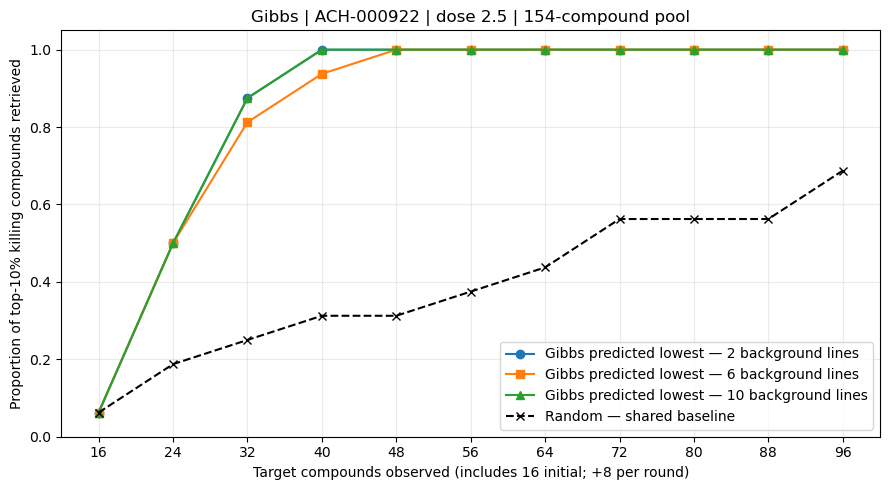

In [5]:
fig, ax = plt.subplots(figsize=(9, 5))
markers = {2: "o", 6: "s", 10: "^"}
for count, trajectory in metrics[metrics.selector.eq("predicted_lowest")].groupby("background_cells"):
    ax.plot(trajectory.compounds_seen, trajectory.top_10pct_retrieval,
            marker=markers[count], label=f"Gibbs predicted lowest — {count} background lines")
ax.plot(random_baseline.compounds_seen, random_baseline.top_10pct_retrieval,
        color="black", linestyle="--", marker="x", label="Random — shared baseline")
ax.set(xlabel=f"Target compounds observed (includes {initial_size} initial; +{batch_size} per round)",
       ylabel="Proportion of top-10% killing compounds retrieved",
       title=f"Gibbs | {target_model} | dose {fixed_dose:g} | {len(target_responses)}-compound pool",
       ylim=(0, 1.05), xticks=random_baseline.compounds_seen)
ax.grid(alpha=.25)
ax.legend()
fig.tight_layout()
fig.savefig(output_dir / "retrieval.png", dpi=150)
plt.show()